In [1]:
"""
03_data_optimization.py

This script demonstrates the ETL (Extract, Transform, Load) and optimization pipeline
used to prepare the raw CoRE-MOF dataset for the Deep Learning FT-Transformer model.
"""

import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler

def optimize_mof_dataset(dataset_path: str):
    """
    Reads the raw Excel dataset, extracts relevant physical properties, 
    cleans missing values, and optimizes them into scaled PyTorch tensors.
    """
    print(f"Loading raw dataset from {dataset_path}...")
    
    # 1. Extraction
    df = pd.read_excel(dataset_path, engine='openpyxl')
    
    # 2. Transformation (Schema Mapping)
    column_mapping = {
        'name': 'MOF_ID',
        'Accessible Surface Area (m^2/g)': 'Surface_Area',
        'Density (cm^3/g)': 'Density',
        'Accessible pore volume (cm^3/g)': 'Pore_Volume',
        'void fraction': 'Void_Fraction'
    }
    df_filtered = df[list(column_mapping.keys())].rename(columns=column_mapping)
    
    # Clean NaN values
    df_filtered = df_filtered.fillna(0)
    print(f"Successfully processed {len(df_filtered)} MOFs.")
    
    # 3. Optimization for Deep Learning (Scaling)
    # Neural Networks require normalized data to prevent vanishing/exploding gradients
    print("Scaling numerical features (Z-Score Normalization)...")
    features = df_filtered[['Surface_Area', 'Density', 'Pore_Volume', 'Void_Fraction']].values
    
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    # 4. Convert to PyTorch Tensors
    tensor_data = torch.tensor(features_scaled, dtype=torch.float32)
    
    print("\nOptimization Complete. Data is ready for the FT-Transformer.")
    print(f"Final Tensor Shape: {tensor_data.shape}") # Expected: (12020, 4)
    
    return tensor_data, df_filtered['MOF_ID'].values

if __name__ == "__main__":
    path = '../../data/coremof.xlsx'
    # optimize_mof_dataset(path)


Loading raw dataset from /Users/saimohith/Documents/Sem-5/Data-Driven/tables/coremof.xlsx...
Raw Data Shape: (12020, 5)
Missing Values Before Cleaning:
MOF_ID           0
Surface_Area     0
Density          0
Pore_Volume      0
Void_Fraction    0
dtype: int64

Successfully cleaned and processed 12020 MOFs.


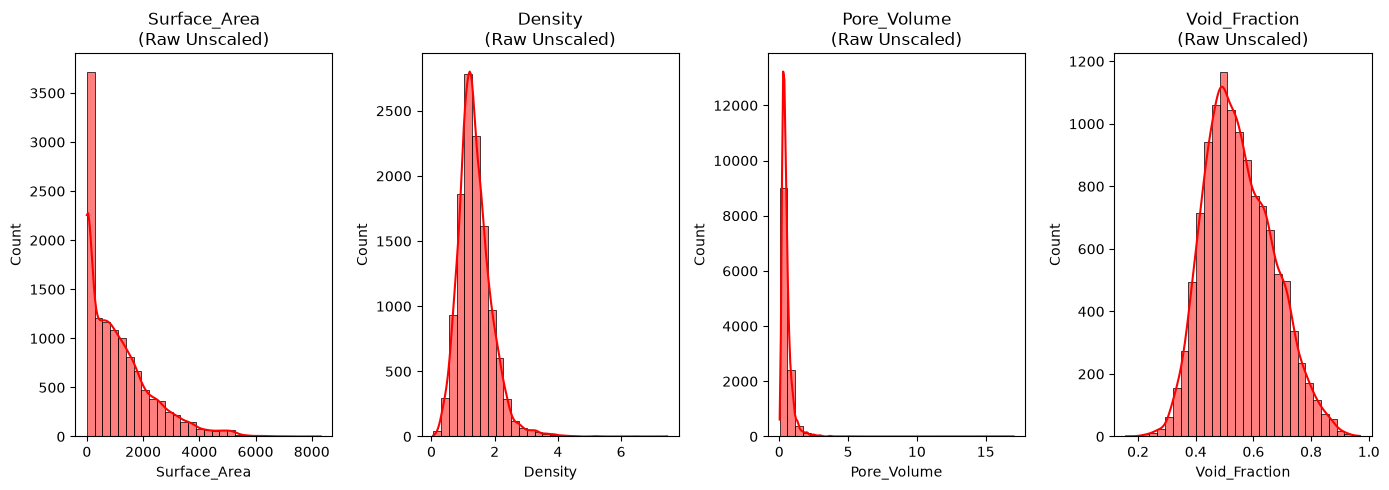


Scaling numerical features (Z-Score Normalization)...


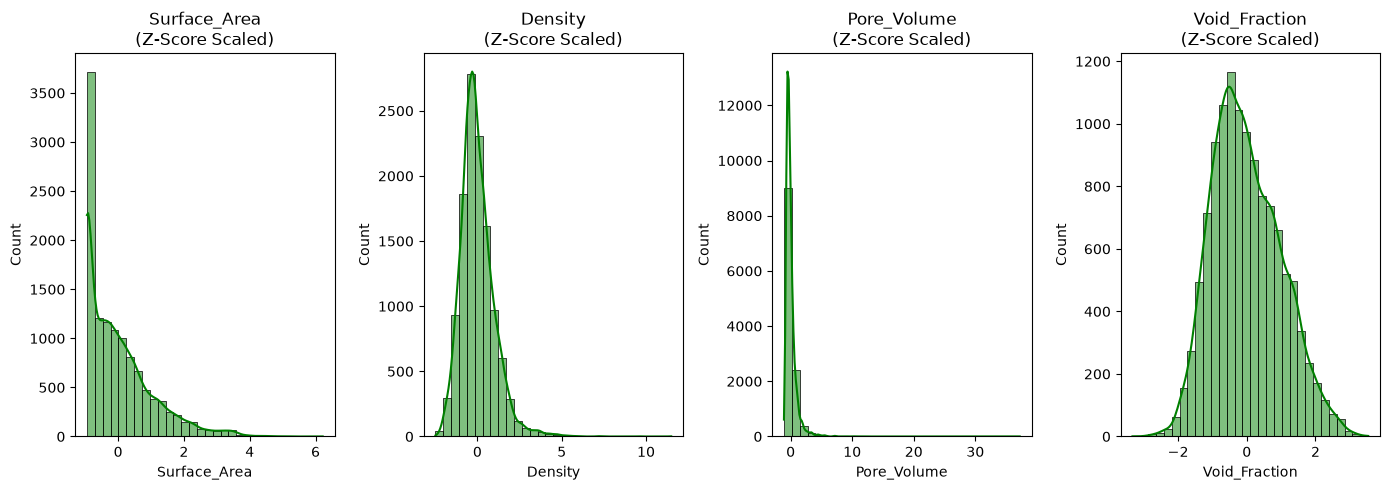


Generating Feature Correlation Heatmap...


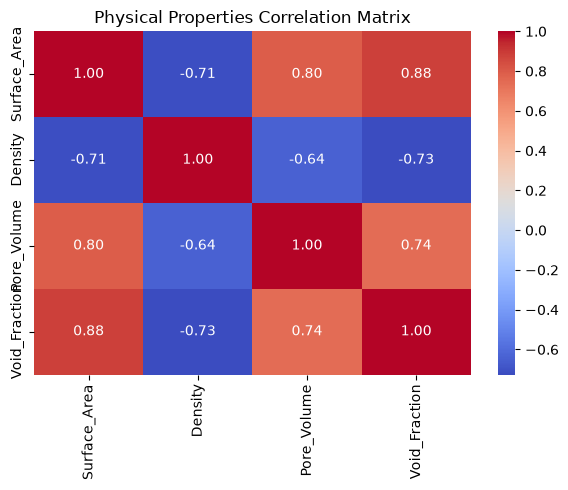


Optimization Complete. Data is ready for the FT-Transformer.
Final Tensor Shape: torch.Size([12020, 4])


In [1]:
"""
03_data_optimization.py

This script demonstrates the ETL (Extract, Transform, Load) and optimization pipeline
used to prepare the raw CoRE-MOF dataset for the Deep Learning FT-Transformer model.
"""

import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

def optimize_mof_dataset(dataset_path: str):
    """
    Reads the raw Excel dataset, extracts relevant physical properties, 
    cleans missing values, scales them, and plots the preprocessing steps!
    """
    print(f"Loading raw dataset from {dataset_path}...")
    
    # 1. Extraction
    df = pd.read_excel(dataset_path, engine='openpyxl')
    
    # 2. Transformation (Schema Mapping)
    column_mapping = {
        'name': 'MOF_ID',
        'Accessible Surface Area (m^2/g)': 'Surface_Area',
        'Density (cm^3/g)': 'Density',
        'Accessible pore volume (cm^3/g)': 'Pore_Volume',
        'void fraction': 'Void_Fraction'
    }
    df_filtered = df[list(column_mapping.keys())].rename(columns=column_mapping)
    
    # Clean NaN values
    print(f"Raw Data Shape: {df_filtered.shape}")
    print(f"Missing Values Before Cleaning:\n{df_filtered.isnull().sum()}\n")
    df_filtered = df_filtered.fillna(0)
    print(f"Successfully cleaned and processed {len(df_filtered)} MOFs.")
    
    # --- VISUALIZATION 1: Before Scaling ---
    plt.figure(figsize=(14, 5))
    for i, col in enumerate(['Surface_Area', 'Density', 'Pore_Volume', 'Void_Fraction']):
        plt.subplot(1, 4, i+1)
        sns.histplot(df_filtered[col], kde=True, color='red', bins=30)
        plt.title(f"{col}\n(Raw Unscaled)")
    plt.tight_layout()
    plt.show()
    
    # 3. Optimization for Deep Learning (Scaling)
    print("\nScaling numerical features (Z-Score Normalization)...")
    features = df_filtered[['Surface_Area', 'Density', 'Pore_Volume', 'Void_Fraction']].values
    
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    # --- VISUALIZATION 2: After Scaling ---
    df_scaled = pd.DataFrame(features_scaled, columns=['Surface_Area', 'Density', 'Pore_Volume', 'Void_Fraction'])
    plt.figure(figsize=(14, 5))
    for i, col in enumerate(df_scaled.columns):
        plt.subplot(1, 4, i+1)
        sns.histplot(df_scaled[col], kde=True, color='green', bins=30)
        plt.title(f"{col}\n(Z-Score Scaled)")
    plt.tight_layout()
    plt.show()
    
    # --- VISUALIZATION 3: Correlation Matrix ---
    print("\nGenerating Feature Correlation Heatmap...")
    plt.figure(figsize=(6, 5))
    sns.heatmap(df_scaled.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Physical Properties Correlation Matrix")
    plt.tight_layout()
    plt.show()
    
    # 4. Convert to PyTorch Tensors
    tensor_data = torch.tensor(features_scaled, dtype=torch.float32)
    
    print("\nOptimization Complete. Data is ready for the FT-Transformer.")
    print(f"Final Tensor Shape: {tensor_data.shape}") 
    
    return tensor_data, df_filtered['MOF_ID'].values

if __name__ == "__main__":
    path = '../../data/coremof.xlsx'
    optimize_mof_dataset(path)
